# Bayesian CART versus RRT: prior sensitivity

The new experiment fixes BCART's $\beta=2$ and compares leaf-mean prior
SDs $\tau\in\{1,2,5,10\}$ with RRT(1), using the same generated data.
The loader prefers the new `bcart_tau_<start>_<end>.pkl` checkpoints.
Until those arrive, it displays the earlier `bcart_...` experiment.
It never pools the two prefixes. Set `RESULT_PREFIX` to select explicitly.

A checkpoint can contain fewer completed replications than its filename's
assigned range; counts below reflect the saved observations.

The four panels show coverage, scaled interval length
($|C_A|\sqrt{n_A}$), test MSE, and inference runtime. Runtime is recorded
in seconds and plotted in minutes. For RRT it excludes tree fitting;
for BCART it includes posterior sampling and interval construction.

In [1]:
from pathlib import Path
import re

import joblib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

In [2]:
# Optional overrides: DATA_DIR = Path("..."); RESULT_PREFIX = "bcart_tau"
DATA_DIR = None
RESULT_PREFIX = None
relative_dir = Path("Simulations/Results/toy_example/bayesianCART")

def checkpoint_paths(directory, prefix):
    pattern = re.compile(rf"{re.escape(prefix)}_(\d+)_(\d+)\.pkl")
    return sorted(
        (path for path in directory.glob(f"{prefix}_*.pkl")
         if pattern.fullmatch(path.name)),
        key=lambda path: tuple(map(int, pattern.fullmatch(path.name).groups())),
    )

# Support kernels started in the notebook folder or anywhere in the repo.
if DATA_DIR is None:
    candidates = [parent / relative_dir for parent in (Path.cwd(), *Path.cwd().parents)]
    candidates.append(Path.cwd())
else:
    candidates = [Path(DATA_DIR)]
prefixes = [RESULT_PREFIX] if RESULT_PREFIX is not None else ["bcart_tau", "bcart"]
discovered = next(
    ((directory, prefix) for prefix in prefixes for directory in candidates
     if checkpoint_paths(directory, prefix)), None)
if discovered is None:
    raise FileNotFoundError("No BCART checkpoints found. Set DATA_DIR and RESULT_PREFIX.")
DATA_DIR, RESULT_PREFIX = discovered
DATA_DIR = DATA_DIR.resolve()
filename_pattern = re.compile(rf"{re.escape(RESULT_PREFIX)}_(\d+)_(\d+)\.pkl")
files_list = checkpoint_paths(DATA_DIR, RESULT_PREFIX)
print(f"Results directory: {DATA_DIR}")
print(f"Selected experiment prefix: {RESULT_PREFIX}")
print(f"Found {len(files_list)} checkpoint files.")

Results directory: /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART
Selected experiment prefix: bcart
Found 20 checkpoint files.


In [3]:
metrics = ["Coverage Rate", "Length", "MSE", "Inference Time"]
frames, progress = [], []
for path in files_list:
    start, end = map(int, filename_pattern.fullmatch(path.name).groups())
    saved = joblib.load(path)
    required = {"Method", "SD(Y)", *metrics}
    if not isinstance(saved, dict) or not required.issubset(saved):
        raise ValueError(f"{path.name}: expected the BCART results dictionary including Inference Time")
    if len({len(saved[key]) for key in required}) != 1:
        raise ValueError(f"{path.name}: result columns have different lengths")
    frame = pd.DataFrame({key: saved[key] for key in ["Method", "SD(Y)", *metrics]})
    if frame.empty:
        continue
    # Each method is recorded once per replication, beginning at start.
    frame["Replication"] = start + frame.groupby("Method", sort=False).cumcount()
    if (frame["Replication"] >= end).any():
        raise ValueError(f"{path.name}: saved rows exceed the assigned segment")
    frame["Source File"] = path.name
    frames.append(frame)
    progress.append({"File": path.name, "Start": start, "End": end,
                     "Saved replications": frame["Replication"].nunique(),
                     "Assigned replications": end - start})

if not frames:
    raise ValueError("The checkpoints contain no saved results")
results = pd.concat(frames, ignore_index=True)
if results.duplicated(["Replication", "Method"]).any():
    raise ValueError("Overlapping checkpoints contain duplicate replication/method rows")
for metric in metrics:
    results[metric] = pd.to_numeric(results[metric], errors="raise")
if results["SD(Y)"].nunique() != 1:
    raise ValueError("These plots expect one noise setting; filter SD(Y) before combining experiments")
results["Inference Time (min)"] = results["Inference Time"] / 60
progress_df = pd.DataFrame(progress)
print(f"Loaded {results['Replication'].nunique()} saved replications across "
      f"{len(progress_df)} files ({len(results)} method/replication rows).")
print("Rows per method:")
print(results.groupby("Method", sort=False).size().to_string())
display(progress_df)

Loaded 119 saved replications across 20 files (357 method/replication rows).
Rows per method:
Method
RRT                      119
BCART(beta=1, tau=10)    119
BCART(beta=2, tau=10)    119


,File,Start,End,Saved replications,Assigned replications
0,bcart_0_50.pkl,0,50,5,50
1,bcart_50_100.pkl,50,100,6,50
2,bcart_100_150.pkl,100,150,6,50
3,bcart_150_200.pkl,150,200,6,50
4,bcart_200_250.pkl,200,250,6,50
5,bcart_250_300.pkl,250,300,6,50
6,bcart_300_350.pkl,300,350,6,50
7,bcart_350_400.pkl,350,400,6,50
8,bcart_400_450.pkl,400,450,6,50
9,bcart_450_500.pkl,450,500,6,50


In [4]:
def method_sort_key(method):
    if method.startswith("RRT"):
        return (0, 0, 0, method)
    match = re.fullmatch(r"BCART\(beta=([^,]+), tau=([^\)]+)\)", method)
    if match:
        return (1, float(match.group(1)), float(match.group(2)), method)
    return (2, 0, 0, method)

method_order = sorted(results["Method"].unique(), key=method_sort_key)
summary = results.groupby("Method").agg(
    Replications=("Replication", "nunique"),
    Coverage=("Coverage Rate", "mean"),
    Scaled_length=("Length", "mean"),
    Test_MSE=("MSE", "mean"),
    Runtime_seconds=("Inference Time", "mean"),
    Runtime_minutes=("Inference Time (min)", "mean"),
).reindex(method_order)
display(summary.round(3))

,Replications,Coverage,Scaled_length,Test_MSE,Runtime_seconds,Runtime_minutes
Method,,,,,,
RRT,119,0.903,6.458,4.677,156.349,2.606
"BCART(beta=1, tau=10)",119,0.913,7.073,4.357,605.607,10.093
"BCART(beta=2, tau=10)",119,0.894,7.195,4.424,608.878,10.148


Boxplots summarize the saved replication-level metrics, with diamonds marking
their means. The dashed coverage line is the nominal 90% level. Outlier points
are hidden for readability, but all finite observations contribute to means.
These partial results are updated by rerunning the notebook after replacing
or adding worker checkpoints.

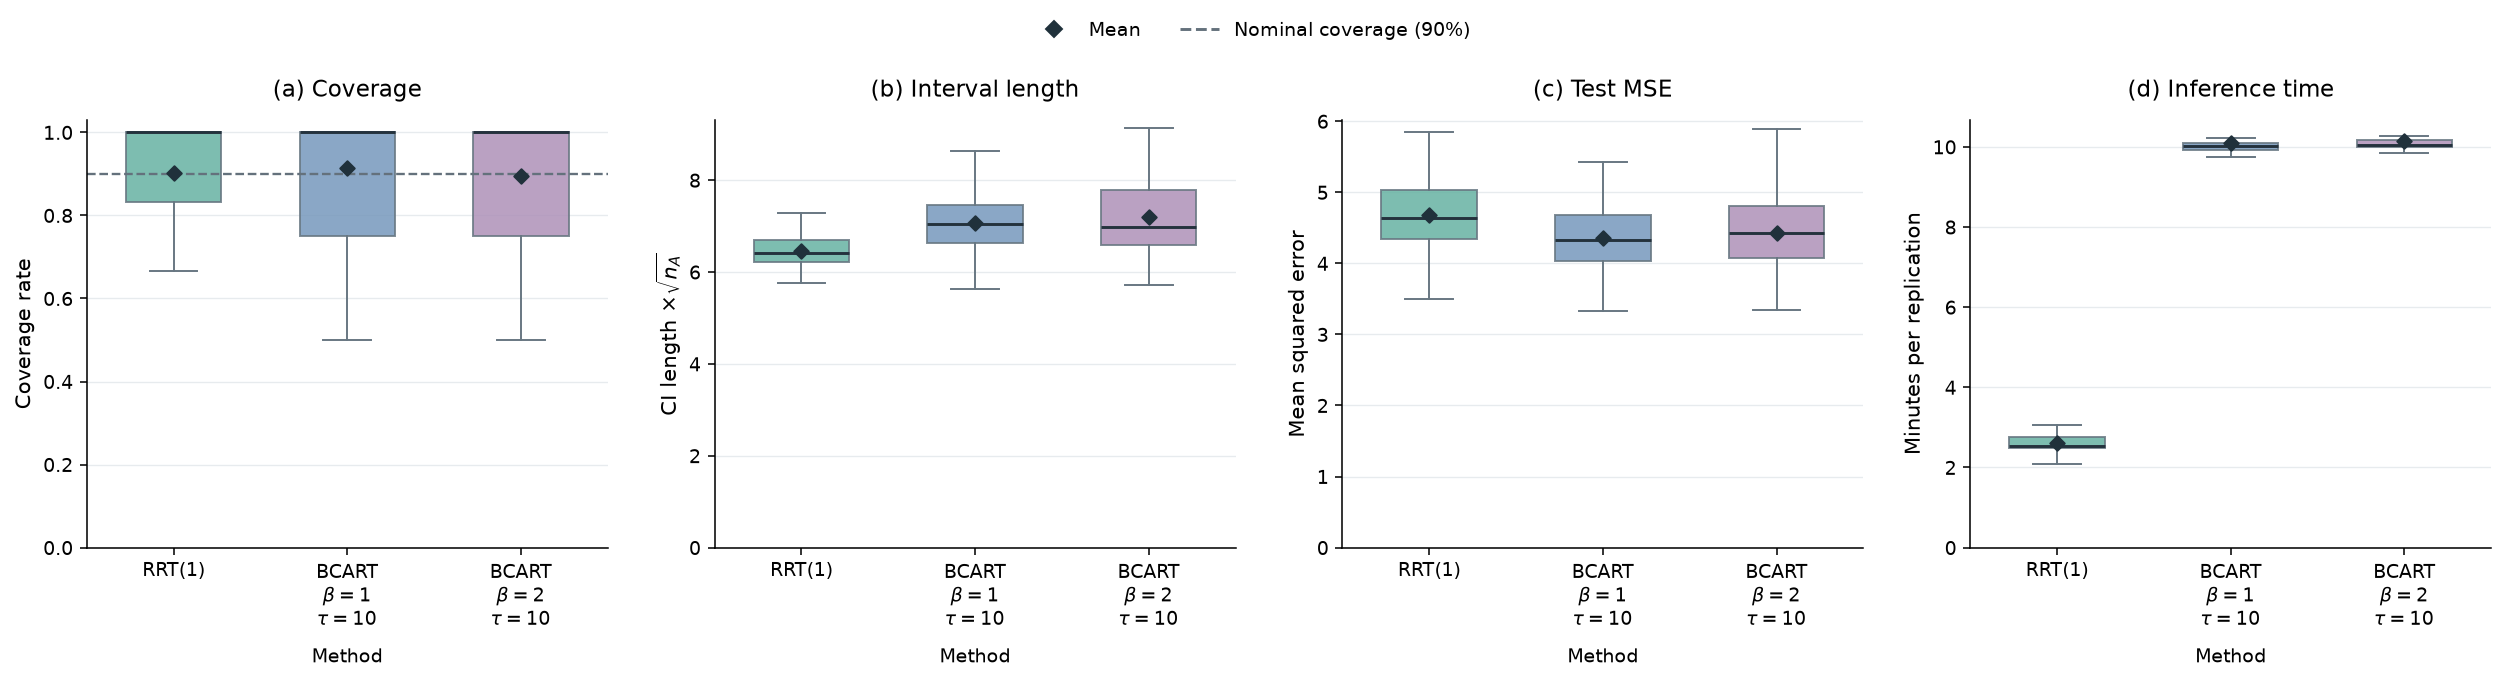

In [5]:
def method_label(method):
    match = re.fullmatch(r"BCART\(beta=([^,]+), tau=([^\)]+)\)", method)
    if match:
        beta, tau = map(float, match.groups())
        return "BCART\n" + rf"$\beta={beta:g}$" + "\n" + rf"$\tau={tau:g}$"
    return "RRT(1)" if method == "RRT" else method

panel_specs = [
    ("Coverage Rate", "(a) Coverage", "Coverage rate"),
    ("Length", "(b) Interval length", r"CI length $\times\sqrt{n_A}$"),
    ("MSE", "(c) Test MSE", "Mean squared error"),
    ("Inference Time (min)", "(d) Inference time", "Minutes per replication"),
]
colors = ["#66B2A2", "#7698BC", "#AE91B8", "#D9A66F", "#A2B879"]
fig, axes = plt.subplots(1, 4, figsize=(max(18, 4 * len(method_order)), 4.8))
for ax, (metric, title, ylabel) in zip(axes, panel_specs):
    values = [results.loc[results["Method"] == method, metric].dropna().to_numpy()
              for method in method_order]
    if any(len(value) == 0 or not np.isfinite(value).all() for value in values):
        raise ValueError(f"Missing or non-finite plot values for {metric}")
    boxes = ax.boxplot(
        values, positions=np.arange(len(method_order)), widths=.55,
        patch_artist=True, showfliers=False,
        medianprops={"color": "#24323D", "linewidth": 1.5},
        whiskerprops={"color": "#687782"}, capprops={"color": "#687782"},
    )
    for index, box in enumerate(boxes["boxes"]):
        box.set(facecolor=colors[index % len(colors)], edgecolor="#687782", alpha=.85)
    ax.scatter(np.arange(len(method_order)), [value.mean() for value in values],
               marker="D", s=28, color="#20313B", zorder=4)
    ax.set_xticks(np.arange(len(method_order)))
    ax.set_xticklabels([method_label(method) for method in method_order], fontsize=10)
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_xlabel("Method", labelpad=8)
    ax.grid(axis="y", color="#DDE3E8", linewidth=.7, alpha=.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    if metric == "Coverage Rate":
        ax.set_ylim(0, 1.03)
        ax.axhline(.9, color="#64717C", linestyle="--", linewidth=1.2)
    else:
        ax.set_ylim(bottom=0)

fig.legend(handles=[
    Line2D([], [], marker="D", linestyle="None", color="#20313B", label="Mean"),
    Line2D([], [], linestyle="--", color="#64717C", label="Nominal coverage (90%)"),
], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, .94), w_pad=2)
plt.show()

In [6]:
output_stem = DATA_DIR / f"{RESULT_PREFIX}_vs_rrt_four_panels"
fig.savefig(output_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(output_stem.with_suffix(".pdf"), bbox_inches="tight")
print(f"Saved {output_stem.with_suffix('.png')}")
print(f"Saved {output_stem.with_suffix('.pdf')}")

Saved /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART/bcart_vs_rrt_four_panels.png
Saved /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART/bcart_vs_rrt_four_panels.pdf
